In [1]:
import numpy as np


def z_over_x(z, rho):
    z = np.asarray(z, dtype=float)
    rho = np.asarray(rho,dtype=float)
    z,rho = np.broadcast_arrays(z, rho)
    result = np.empty_like(z)
    mask = np.abs(z)< 1e-6
    nonmask = np.abs(z)>= 1e-6
    result[mask] = 1-rho[mask]*z[mask]/2+(2-3*rho[mask]**2)*z[mask]**2/12 #Taylor expansion,might need to be clarified in the article
    result[nonmask] = z[nonmask]/(np.log((np.sqrt(1-2*rho[nonmask]*z[nonmask]+z[nonmask]**2)+z[nonmask]-rho[nonmask])/(1-rho[nonmask])))
    return result

In [2]:
def hagan_iv(F, K, T, alpha, beta, rho, nu):
    K = np.asarray(K,dtype=float)
    L = np.log(F/K)
    p=(F*K)**((1-beta)/2)
    z=nu/alpha*p*L
    D=p*(1+(1-beta)**2/24*L**2+(1-beta)**4/1920*L**4)
    A = (1-beta)**2*alpha**2/(24*p**2)+rho*beta*nu*alpha/4/p+(2-3*rho**2)*nu**2/24
    sigma = alpha/D* z_over_x(z,rho)*(1+A*T)
    return sigma

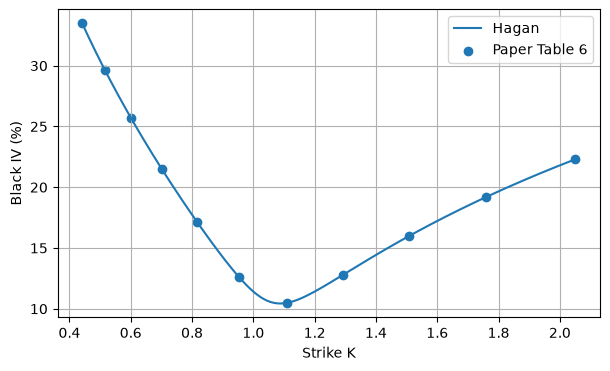

In [3]:
import matplotlib.pyplot as plt

F = 1.0
beta = 1.0
T = 1.6316
alpha = 0.108266
rho = -0.464053
nu = 0.887903

K_table = np.array([
    0.4419, 0.5152, 0.6007, 0.7004, 0.8166, 0.9520,
    1.1100, 1.2941, 1.5088, 1.7591, 2.0509,
])

iv_paper = np.array([
    33.47, 29.66, 25.70, 21.54, 17.14, 12.64,
    10.49, 12.82, 16.00, 19.19, 22.31,
]) / 100

iv_table = hagan_iv(F,K_table,T,alpha,beta,rho,nu)
max_error = np.max(np.abs(iv_table-iv_paper))*10000
K_grid = np.linspace(np.min(K_table),np.max(K_table),300)
iv_grid = hagan_iv(F,K_grid,T,alpha,beta,rho,nu)


fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_grid, iv_grid * 100, label="Hagan")
ax.scatter(K_table, iv_paper * 100, label="Paper Table 6")
ax.set_xlabel("Strike K")
ax.set_ylabel("Black IV (%)")
ax.legend()
ax.grid()
plt.show()

In [4]:
def make_strikes(F, T, alpha, rho, nu):
    u = nu**2*T
    v_bar = alpha**2*np.expm1(u)/u
    delta_sigma = alpha*(np.expm1(-u/2+1.5*nu*T**0.5))
    n_grid = np.linspace(-3.5,3.5,10)
    K = F*np.exp(-0.5*v_bar*T+rho/nu*delta_sigma+n_grid*np.sqrt(v_bar*T))
    return K 
    

In [5]:
def sample_parameters(n, t_min, t_max, seed=42):
    rng = np.random.default_rng(seed)
    T = rng.uniform(t_min,t_max,n)
    alpha = rng.uniform(0.05,0.5,n)
    nu_1m = rng.uniform(0.05,4,n)
    rho = rng.uniform(-0.9,0.9,n)
    nu = nu_1m*np.sqrt(1/12/T)
    return np.column_stack((T,alpha,nu,rho))



In [6]:
def build_dataset(P):
    n = P.shape[0]
    X = np.empty((n,14),dtype=float)
    y = np.empty((n,10),dtype=float)
    for i , row in enumerate(P):
         T, alpha, nu, rho = row
         K = make_strikes(1,T,alpha,rho=rho,nu=nu)
         iv = hagan_iv(1,K,T,alpha,1,rho,nu)
         X[i,:4]=row
         X[i,4:]=K
         y[i,:] = iv
    return X,y

In [7]:
def grid_parameters(t_min, t_max):
    T_grid = np.linspace(t_min,t_max,100)
    alpha_grid = np.linspace(0.05,0.5,10)
    nu_1m_grid = np.linspace(0.05,4,10)
    rho_grid = np.linspace(-0.9,0.9,10)
    T_mesh, alpha_mesh, nu_1m_mesh, rho_mesh = np.meshgrid(
    T_grid,
    alpha_grid,
    nu_1m_grid,
    rho_grid,
    indexing="ij",
)
    nu_mesh = nu_1m_mesh*np.sqrt(1/12/T_mesh)
    T_mesh = T_mesh.ravel()
    alpha_mesh = alpha_mesh.ravel()
    rho_mesh = rho_mesh.ravel()
    nu_mesh = nu_mesh.ravel()
    return np.column_stack((T_mesh,alpha_mesh,nu_mesh,rho_mesh))

In [8]:
t_min, t_max = 1/365, 1.0
train_seed, test_seed, shuffle_seed = 42, 43, 44

from src.config import DATA_DIR

file_path = DATA_DIR / "hagan_1d_1y.npz"
rng = np.random.default_rng(shuffle_seed)
P_grid = grid_parameters(t_min,t_max)
P_random = sample_parameters(150000,t_min,t_max,train_seed)
P_test = sample_parameters(50000,t_min,t_max,test_seed)
P_train = np.vstack((P_grid,P_random))
order = rng.permutation(P_train.shape[0])
P_train[order] = P_train
X_train,y_train = build_dataset(P_train)
X_test,y_test = build_dataset(P_test)

In [37]:
np.savez_compressed(
    file_path,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    t_range=np.array([t_min, t_max]),
    seeds=np.array([train_seed, test_seed, shuffle_seed]),
    strike_rule="table_3_4_unconditional_variance",
)